# P2. Second Practical Assignment
# Big Data and Business Analytics 


## <span style="color:green">Index</span>
### 1. Exploratory data analysis
### 2. Transformation of the data
### 3. Training and testing machine learning models
### 4. Best behaving model for prediction purposes
### 5. Provide predictions for 20 instances

### <span style="color:blue">Step 1. Exploratory data analysis</span>

The first thing we did was upload all the libraries that we are going to be using throught this process. From the basic ones to upload, manage and transform the datasets, to the ones to make the visualization of data and also the ones that help us create, train, and obtain the accuracy an recall of each one of the machine learning models.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import recall_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier 
from sklearn.model_selection import GridSearchCV, KFold

Then, naturally we uploaded the whole dataset, keeping in mind the decimal ',' and the delimiter that divides the columns and the delimiter ';' to make sure each column and row were properlly representated.

In [2]:
dfMGdataset_P2 = pd.read_csv("MGdataset_P2.csv", decimal=",", delimiter=';')
dfMGdataset_P2

,O_order,O_code,O_dlots,O_Nlot,O_aval,O_daval,O_year_p,O_countryp_code,O_finstr,R_bids,...,O_dnegotiated,O_scope,E_Pref,R_pcost,E_indice,O_catpro,E_GDP_1,E_DTF_1,E_distance,viable
0,119,131769,1,1,50000.0,1,2015,TK,IPA,1.0,...,0,0,3333333.33,2989000.00,0.8967,3,1025.467,72.83,2477,0
1,121,133560,1,1,40000.0,1,2015,TK,IPA,1.0,...,0,0,2666666.67,2749000.00,1.0309,3,1025.467,72.83,2995,0
2,125,135520,1,2,750.0,1,2015,SB,IPA,1.0,...,0,0,50000.00,39077.00,0.7815,3,39.882,72.48,1370,0
3,126,135612,1,2,2500.0,1,2017,TK,IPA,1.0,...,1,0,166666.67,153580.00,0.9215,3,1122.512,73.26,2975,0
4,130,135853,1,2,18581.0,1,2014,LB,ENI,1.0,...,0,0,1238733.33,1217912.00,0.9832,3,40.910,71.87,3136,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
387,493,131546,1,1,27500.0,1,2015,TK,IPA,NaN,...,0,0,1833333.33,2880996.30,1.5715,3,1025.467,72.83,2761,1
388,500,137249,1,2,1000.0,1,2015,JO,ENI,NaN,...,0,0,66666.67,54041.00,0.8106,2,29.501,78.20,3324,1
389,507,138256,1,1,3500.0,1,2016,ME,IPA,NaN,...,0,0,233333.33,348330.47,1.4928,2,4.529,79.37,1466,1
390,508,138256,1,2,6000.0,1,2016,ME,IPA,NaN,...,0,0,400000.00,580000.00,1.4500,2,4.529,79.37,1466,1


To get a better picture, we printed the names of the columns and we wrote again what each of them meant.

In [3]:
print(dfMGdataset_P2.columns)

Index(['O_order', 'O_code', 'O_dlots', 'O_Nlot', 'O_aval', 'O_daval',
       'O_year_p', 'O_countryp_code', 'O_finstr', 'R_bids', 'R_dbids',
       'O_dnegotiated', 'O_scope', 'E_Pref', 'R_pcost', 'E_indice', 'O_catpro',
       'E_GDP_1', 'E_DTF_1', 'E_distance', 'viable'],
      dtype='object')


O_order: It is the order given by WINWITHUS to each instance in the dataset.
O_code: It is a unique reference code for each procurement process.
O_dlots: It indicates whether the procurement is for a single lot (0) or several lots (1).
O_Nlot: It indicates the number of the lot procured.
O_aval: It is the amount to be deposited as a guarantee to participate in the process.
O_daval: It indicates whether the process requires to deposit a bank guarantee.
O_year_p: It is the year in which the procurement process was called.
O_countryp_code: It is an identifier of the country where the process took place.
O_finstr: It is a geographic code representing the financial instrument funding the procurement.
R_bids: It is the number of bids received (from different bidders).
R_dbids: It indicates whether at least one valid bid was received.
O_dnegotiated: It indicates whether the price of the lot is open to further negotiation.
O_scope: It indicates whether the lot is open to international bidders (or national ones only).
E_Pref: It is the engineered price of reference of the procured lot.
R_pcost: It is the actual winning price of the procurement process.
E_indice: It is an engineered index relating the winning price to the engineered reference price.
O_catpro: It is the category of the product sold in the procurement process.
E_GDP_1: Engineered value of the country GDP.
E_DTF_1: Engineered variable for the openness of the country to foreign trade.
E_distance: Engineered average distance to the point of delivery of the lot.

A statistical represntation of the data was a necessity to understand furthermore which columns are more relevant for our objective, the size of the numbers we are working with, and any other detail that can help us get a deeper understanding of the data.

In [4]:
dfMGdataset_P2.describe()

,O_order,O_code,O_dlots,O_Nlot,O_aval,O_daval,O_year_p,R_bids,R_dbids,O_dnegotiated,O_scope,E_Pref,R_pcost,E_indice,O_catpro,E_GDP_1,E_DTF_1,E_distance,viable
count,392.000000,392.000000,392.000000,392.000000,392.000000,392.0,392.000000,375.000000,392.0,392.000000,392.000000,3.920000e+02,3.920000e+02,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000
mean,313.500000,136669.127551,0.846939,2.334184,10670.175153,1.0,2015.571429,3.474667,1.0,0.063776,0.165816,7.113450e+05,6.459919e+05,0.987616,2.512755,418.003291,72.403571,2147.147959,0.522959
std,113.304898,1762.161209,0.360507,1.606590,40570.288107,0.0,0.956870,2.071909,0.0,0.244665,0.372391,2.704686e+06,2.348074e+06,0.362341,1.006293,501.338729,3.548304,685.577744,0.500111
min,118.000000,128615.000000,0.000000,1.000000,100.000000,1.0,2014.000000,1.000000,1.0,0.000000,0.000000,6.666670e+03,2.608960e+03,0.066900,1.000000,4.304000,63.280000,1307.000000,0.000000
25%,215.750000,135881.750000,1.000000,1.000000,1500.000000,1.0,2015.000000,2.000000,1.0,0.000000,0.000000,1.000000e+05,1.055910e+05,0.744050,2.000000,10.925000,71.150000,1563.000000,0.000000
50%,313.500000,136950.500000,1.000000,2.000000,3500.000000,1.0,2015.000000,3.000000,1.0,0.000000,0.000000,2.333333e+05,2.330597e+05,0.928050,3.000000,40.910000,72.830000,1895.000000,1.000000
75%,411.250000,137911.000000,1.000000,3.000000,8000.000000,1.0,2016.000000,5.000000,1.0,0.000000,0.000000,5.333333e+05,4.852624e+05,1.198200,3.000000,1025.467000,73.260000,2658.000000,1.000000
max,509.000000,139157.000000,1.000000,9.000000,600000.000000,1.0,2017.000000,17.000000,1.0,1.000000,1.000000,4.000000e+07,2.967688e+07,2.821600,4.000000,1122.512000,87.740000,3324.000000,1.000000


Right away we detected that two of the columns (O_daval and R_dbids) were the same value throught the whole dataset, so we decided to drop them on the second step. Nevertheless we kept analyzing the other data and trying to see if even tho the number is the same, maybe they provided us relevant information to help our model.

The next step we took was to separat the columns in categorical variables (strings or other non-numeric values) numerical variables (integers or floating-point numbers) which further helps us identify and categorize the columns in our DataFrame. And also gives us a picture that we will need to use some Encoding and Scaling before training the model.

In [5]:
cat_cols=dfMGdataset_P2.select_dtypes(include=['object']).columns
num_cols = dfMGdataset_P2.select_dtypes(include=np.number).columns.tolist()
print("Categorical Variables:")
print(cat_cols)
print("Numerical Variables:")
print(num_cols)

Categorical Variables:
Index(['O_countryp_code', 'O_finstr'], dtype='object')
Numerical Variables:
['O_order', 'O_code', 'O_dlots', 'O_Nlot', 'O_aval', 'O_daval', 'O_year_p', 'R_bids', 'R_dbids', 'O_dnegotiated', 'O_scope', 'E_Pref', 'R_pcost', 'E_indice', 'O_catpro', 'E_GDP_1', 'E_DTF_1', 'E_distance', 'viable']


And then chose this two graphs that represent the whole dataset first fith boxplots and then with a correlation matrix, even tho we were going to be analyzing each category individually further on the document.

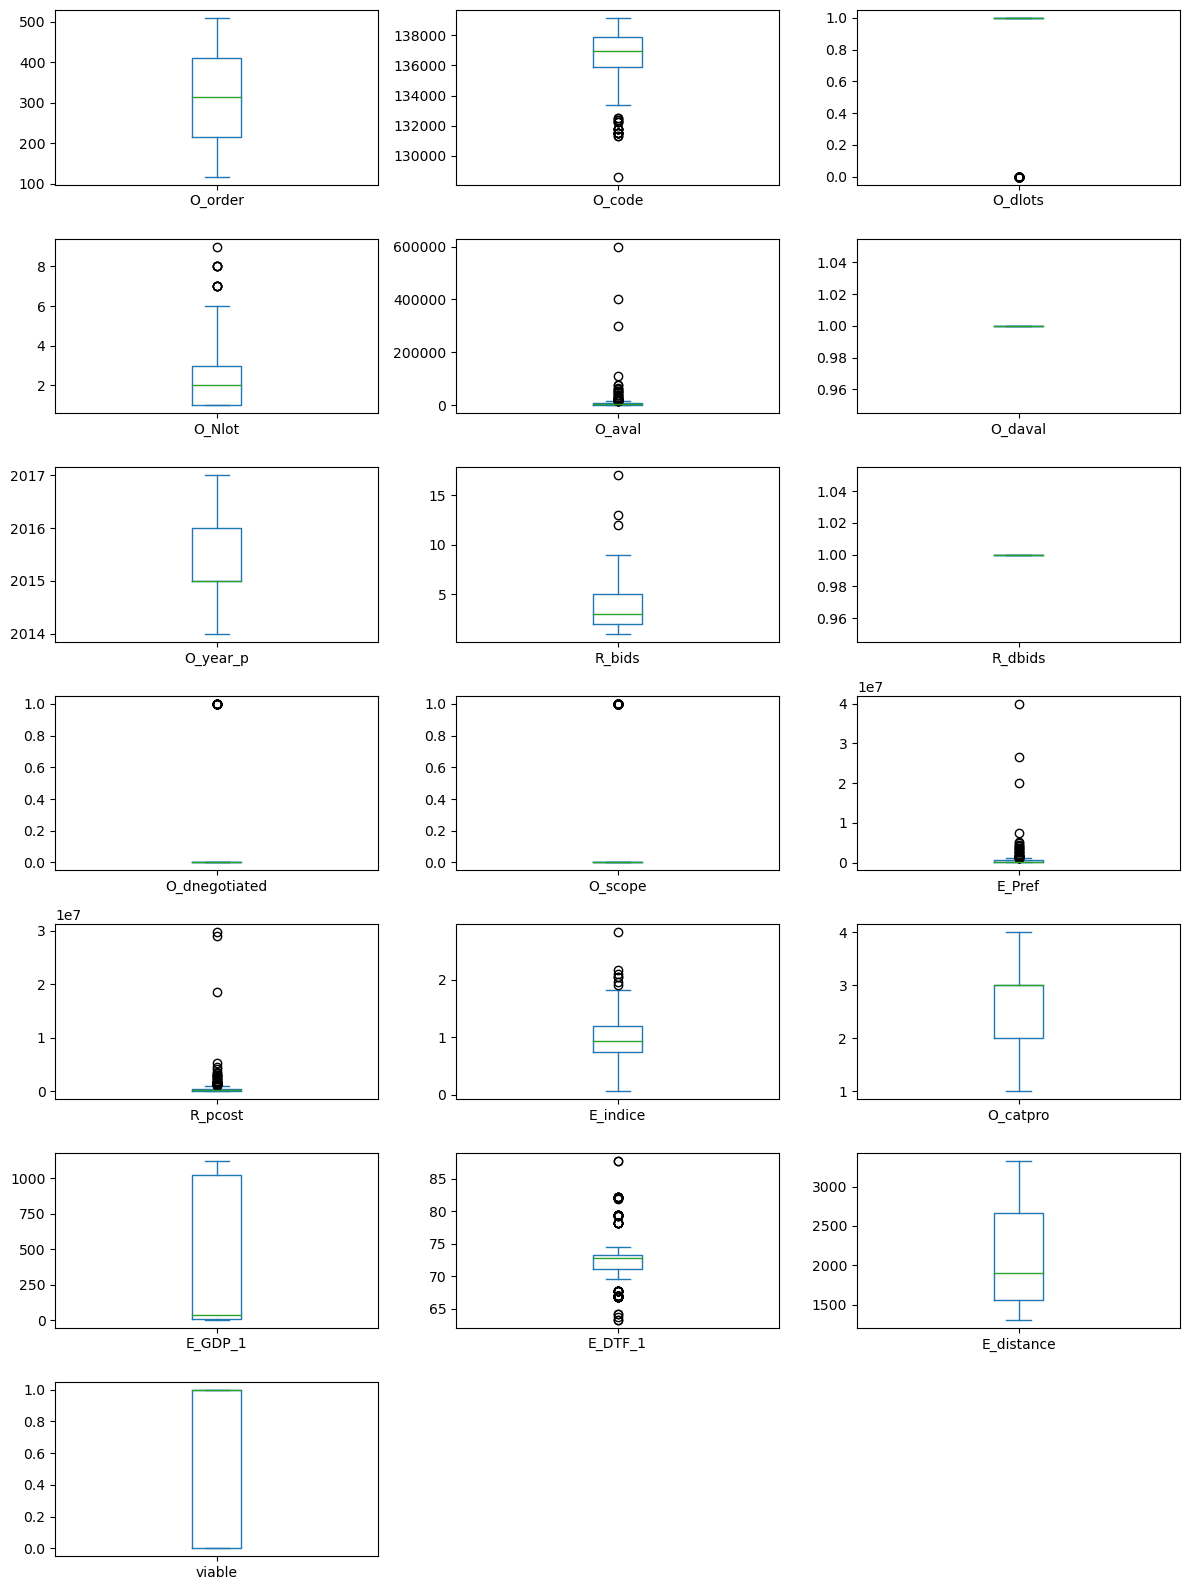

Text(0.5, 1.0, 'Correlation Matrix')

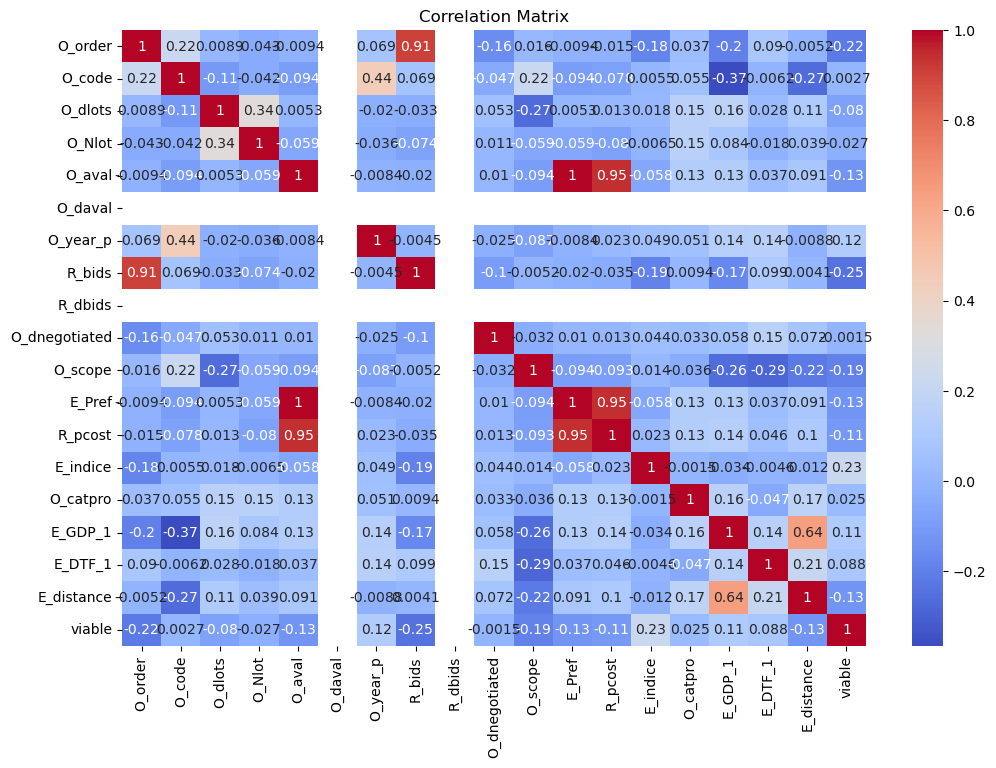

In [6]:
#Boxplot representation
dfMGdataset_P2.plot(kind='box', subplots=True, layout=(7,3), figsize=(12, 16),sharex=False, sharey=False)
plt.tight_layout()
plt.show()

#Correlation matrix
numerical_features = dfMGdataset_P2.select_dtypes(include=['int64', 'float64'])
correlation_matrix = numerical_features.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')

This next piece of code provides us better information about the type of values each column has (float, integer or object), if there are any missing values, and the total number of columns and rows.

In [7]:
dfMGdataset_P2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   O_order          392 non-null    int64  
 1   O_code           392 non-null    int64  
 2   O_dlots          392 non-null    int64  
 3   O_Nlot           392 non-null    int64  
 4   O_aval           392 non-null    float64
 5   O_daval          392 non-null    int64  
 6   O_year_p         392 non-null    int64  
 7   O_countryp_code  392 non-null    object 
 8   O_finstr         392 non-null    object 
 9   R_bids           375 non-null    float64
 10  R_dbids          392 non-null    int64  
 11  O_dnegotiated    392 non-null    int64  
 12  O_scope          392 non-null    int64  
 13  E_Pref           392 non-null    float64
 14  R_pcost          392 non-null    float64
 15  E_indice         392 non-null    float64
 16  O_catpro         392 non-null    int64  
 17  E_GDP_1         

And then, this variable helped us distinguish how many unique values does each column have which was very useful to get a sense of the number of lots, how many different years does the data represent, how many different countries are in our dataset, how many categories... and it also shows us once again that O_daval and R_dbids have only one value throught the dataset. 

In [8]:
dfMGdataset_P2.nunique()

O_order            392
O_code             183
O_dlots              2
O_Nlot               9
O_aval             130
O_daval              1
O_year_p             4
O_countryp_code     13
O_finstr             3
R_bids              12
R_dbids              1
O_dnegotiated        2
O_scope              2
E_Pref             130
R_pcost            387
E_indice           380
O_catpro             4
E_GDP_1             37
E_DTF_1             26
E_distance          45
viable               2
dtype: int64

The O_dlots column represents if the procurement is for a single lot or for several lots. And here we can see that there are 60 single lots ans 332 several lots.

In [9]:
single_lot = len(dfMGdataset_P2[dfMGdataset_P2['O_dlots'] == 0])
print("Single lots:", single_lot)

several_lots = len(dfMGdataset_P2[dfMGdataset_P2['O_dlots'] == 1])
print("Several lots:", several_lots)

Single lots: 60
Several lots: 332


We also grouped the unique number of lots, that ranges through 1 to 9 and the number of times each one of them were repeated on the original dataset.

In [10]:
grouped_unique_Nlot_dfMGdataset_P2 = dfMGdataset_P2.groupby('O_Nlot')
group_unique_Nlot_countsMGdataset_P2 = grouped_unique_Nlot_dfMGdataset_P2.size()
group_unique_Nlot_countsMGdataset_P2

O_Nlot
1    164
2     89
3     62
4     37
5     17
6     13
7      5
8      4
9      1
dtype: int64

As we can clearly see, our data goes from 2014 to 2017, with the most bidds in the year 2015.

In [11]:
grouped_O_year_p_dfMGdataset_P2 = dfMGdataset_P2.groupby('O_year_p')
group_unique_year_countsMGdataset_P2 = grouped_O_year_p_dfMGdataset_P2.size()
group_unique_year_countsMGdataset_P2

O_year_p
2014     48
2015    155
2016    106
2017     83
dtype: int64

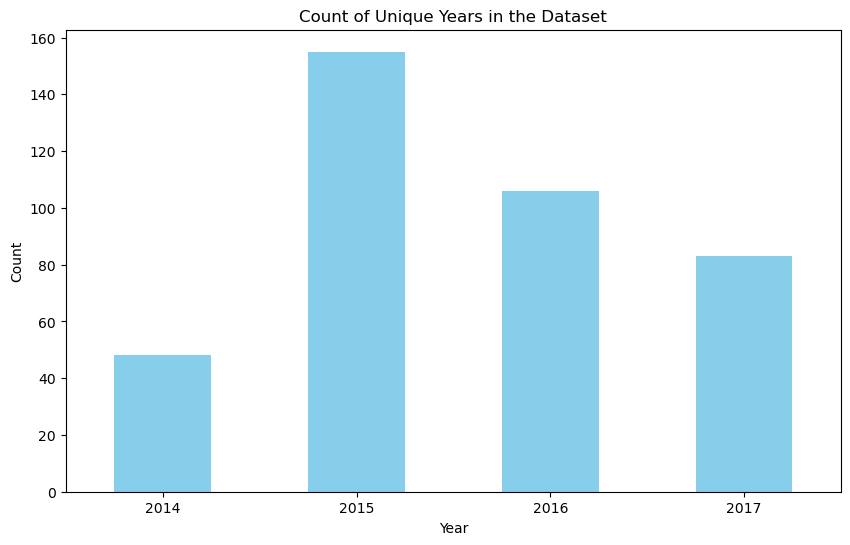

In [12]:
plt.figure(figsize=(10, 6)) 
group_unique_year_countsMGdataset_P2.plot(kind='bar', color='skyblue')
plt.xlabel('Year')
plt.xticks(rotation=0)
plt.ylabel('Count')
plt.title('Count of Unique Years in the Dataset')
plt.show()

 ### Characterization of the Geographic Markets

After that, to sum up in one place all the regions that compose the dataframe and to characterize the Geographic Markets, we used this next piece of code:

In [13]:
unique_regions = dfMGdataset_P2['O_countryp_code'].unique()
unique_regions

array(['TK', 'SB', 'LB', 'XK', 'MO', 'DZ', 'BA', 'EG', 'ME', 'MK', 'AL',
       'TN', 'JO'], dtype=object)

And then we counted how many rows for each region, and we represented it with the next graph and we were ale to see what countries had more bids, and therefore bidders, and which ones didn't have as many.

In [14]:
grouped_dfMGdataset_P2 = dfMGdataset_P2.groupby('O_countryp_code')
group_countsMGdataset_P2 = grouped_dfMGdataset_P2.size()
group_countsMGdataset_P2

O_countryp_code
AL     10
BA     32
DZ      5
EG     10
JO      8
LB     27
ME     12
MK     43
MO      5
SB     28
TK    146
TN      9
XK     57
dtype: int64

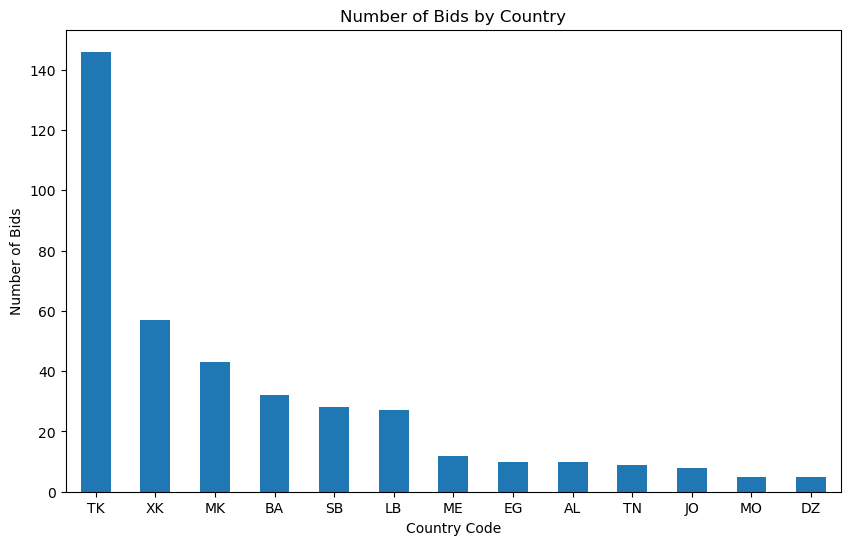

In [15]:
bids_by_country =dfMGdataset_P2['O_countryp_code'].value_counts()

plt.figure(figsize=(10, 6))
bids_by_country.plot(kind='bar')
plt.xlabel('Country Code')
plt.ylabel('Number of Bids')
plt.xticks(rotation=0)
plt.title('Number of Bids by Country')
plt.show()

Out of all this countries, and the total of 392 bids recorded in out dataset, only 65 of the bids where open to international bidders. Most of them were narional only.

In [16]:
national = len(dfMGdataset_P2[dfMGdataset_P2['O_scope'] == 0])
print("National bidders only:", national)

international = len(dfMGdataset_P2[dfMGdataset_P2['O_scope'] != 0])
print("Open to international bidders:", international)

National bidders only: 327
Open to international bidders: 65


Next, we represented the GDP of each country, by year and we were able to see the size of the economy, and also that not all countries have bids every year, in out dataset. Thanks to this chart we figured out that the year is already represented on the GPD as well as the countries, each have their unique numbers for each year. So we decided to drop the year columns as well as the countrie code columns and therefore avoid redundant calculations in our model.

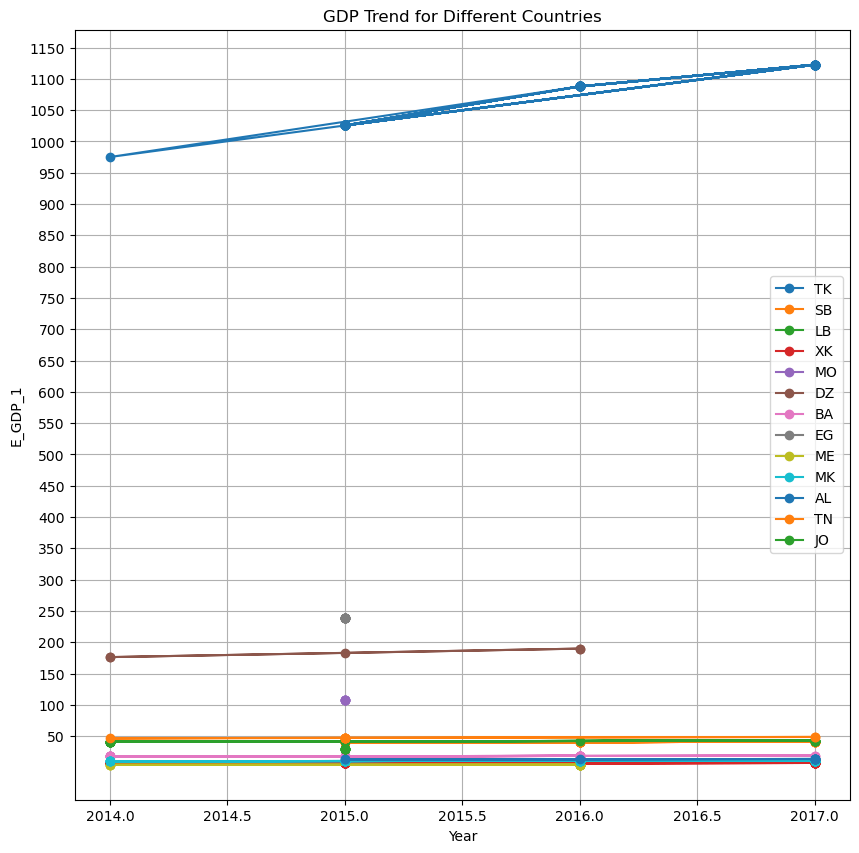

In [17]:
plt.figure(figsize=(10, 10)) 

for each_country in unique_regions:
    filtered_data = dfMGdataset_P2[dfMGdataset_P2['O_countryp_code'] == each_country]  
    
    plt.plot(filtered_data['O_year_p'], filtered_data['E_GDP_1'], marker='o', label=each_country)

plt.xlabel('Year')
plt.ylabel('E_GDP_1')
plt.yticks(np.arange(50, 1200, 50))
plt.title('GDP Trend for Different Countries')
plt.legend()
plt.grid(True)
plt.show()

On the next three pieces of code we can see represented the financial instrument funding the procurements. And on the bar graph we can see them divided by country.

In [18]:
unique_O_finstr = dfMGdataset_P2['O_finstr'].unique()
unique_O_finstr

array(['IPA', 'ENI', 'EULEX'], dtype=object)

In [19]:
grouped_O_finstr_dfMGdataset_P2 = dfMGdataset_P2.groupby('O_finstr')
group_O_finstr_MGdataset_P2 = grouped_O_finstr_dfMGdataset_P2.size()
group_O_finstr_MGdataset_P2

O_finstr
ENI       64
EULEX     51
IPA      277
dtype: int64

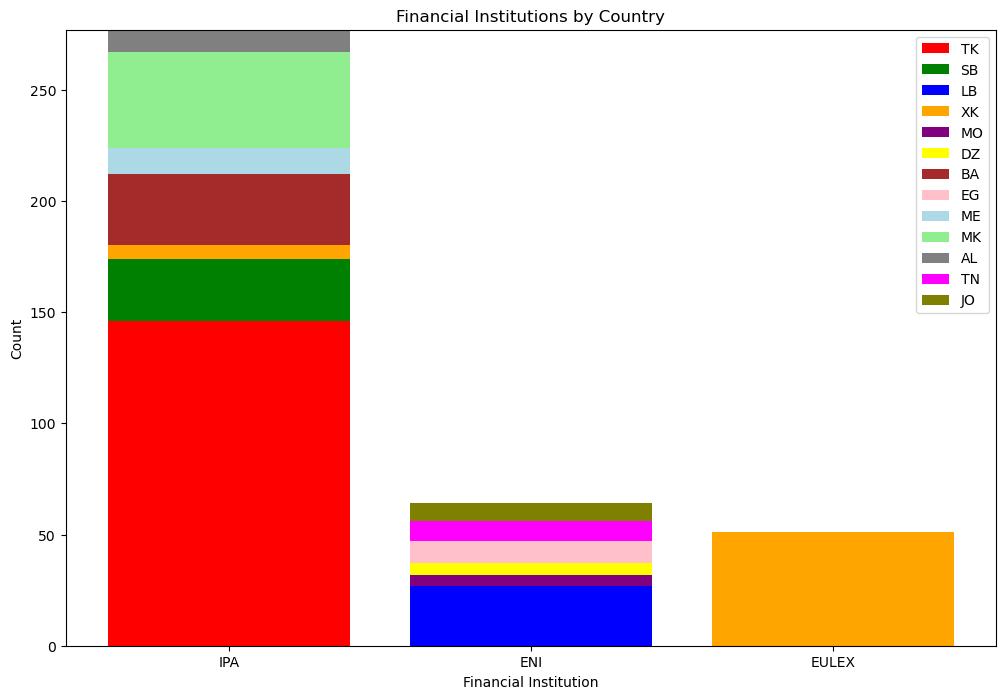

In [20]:
unique_O_finstr = dfMGdataset_P2['O_finstr'].unique()
institution_counts_by_country = {}
colors = ['#FF0000', '#008000', '#0000FF', '#FFA500', '#800080', '#FFFF00', '#A52A2A', '#FFC0CB', '#ADD8E6', '#90EE90', '#808080', '#FF00FF', '#808000', '#808000', '#F08080']
for idx, each_country in enumerate(unique_regions):
    filtered_data = dfMGdataset_P2[dfMGdataset_P2['O_countryp_code'] == each_country]
    institution_counts = filtered_data['O_finstr'].value_counts().reindex(unique_O_finstr, fill_value=0)
    institution_counts_by_country[each_country] = institution_counts

plt.figure(figsize=(12, 8))
ind = np.arange(len(unique_O_finstr))

bottom_values = np.zeros(len(unique_O_finstr))
for idx, (country, counts) in enumerate(institution_counts_by_country.items()):
    plt.bar(ind, counts, label=country, bottom=bottom_values, color=colors[idx % len(colors)])
    bottom_values += counts

plt.xlabel('Financial Institution')
plt.xticks(ind, unique_O_finstr, rotation='vertical')
plt.ylabel('Count')
plt.title('Financial Institutions by Country')
plt.xticks(rotation=0)
plt.legend()
plt.show()


### Characterization of the Project Categories procured

Now we tried to get a deeper understanding of the categories of the products. We found out there are 4 categories and how many bids there were for each category.

In [21]:
unique_categories = dfMGdataset_P2['O_catpro'].unique()
unique_categories

array([3, 1, 4, 2])

In [22]:
grouped_categories_dfMGdataset_P2 = dfMGdataset_P2.groupby('O_catpro')
grouped_categories_dfMGdataset_P2.size()

O_catpro
1     80
2    100
3    143
4     69
dtype: int64

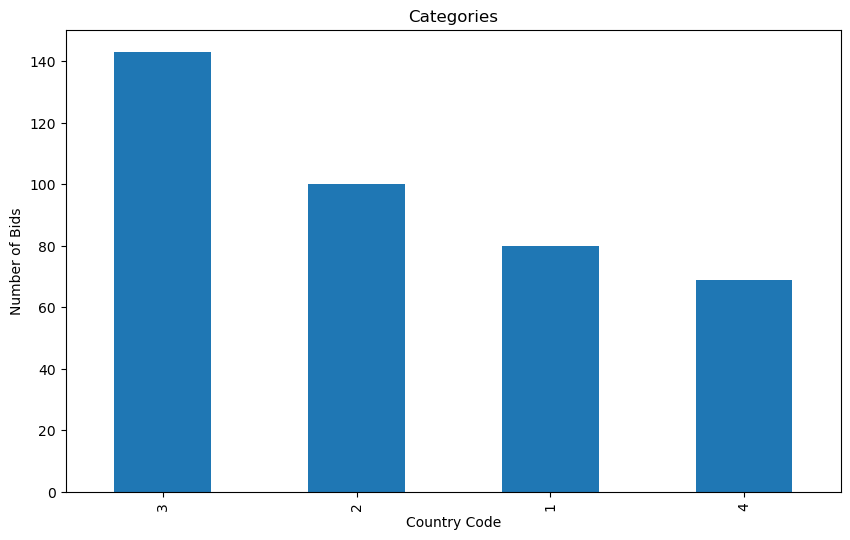

In [23]:
orders_by_country =dfMGdataset_P2['O_catpro'].value_counts()

plt.figure(figsize=(10, 6))
orders_by_country.plot(kind='bar')
plt.xlabel('Country Code')
plt.ylabel('Number of Bids')
plt.title('Categories')
plt.show()

We even groped the categories by the amount of money deposited to participate in the bidding process. Category 4 was the one with the most amout of money needed to participate, even tho is was also the one with the least bids on our dataset.

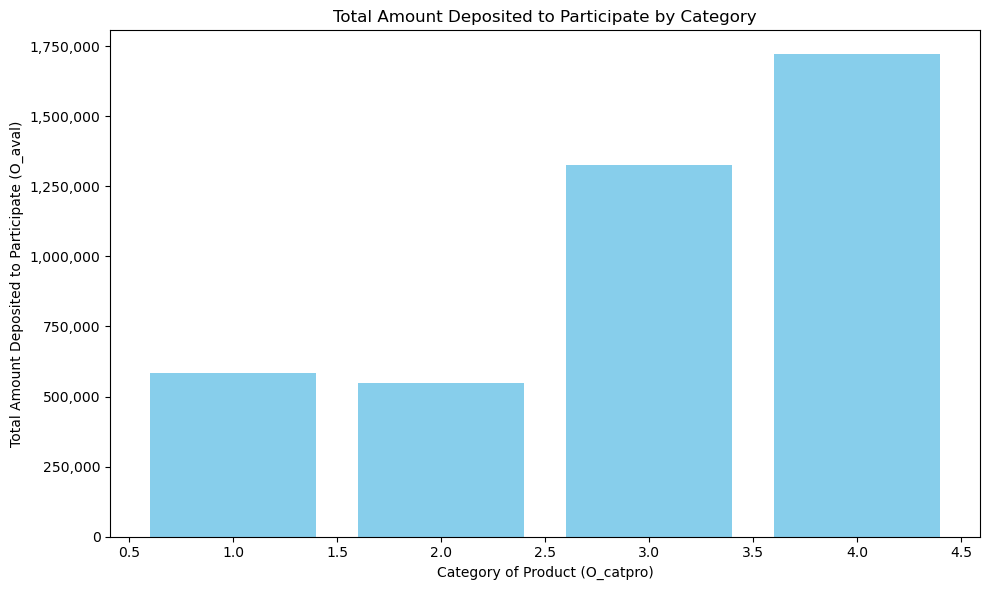

In [24]:
grouped_data = dfMGdataset_P2.groupby('O_catpro')['O_aval'].sum()
plt.figure(figsize=(10, 6))
plt.bar(grouped_data.index, grouped_data.values, color='skyblue')
plt.xlabel('Category of Product (O_catpro)')
plt.ylabel('Total Amount Deposited to Participate (O_aval)')
plt.title('Total Amount Deposited to Participate by Category')
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda x, _: '{:,.0f}'.format(x)))
plt.tight_layout()
plt.show()

So we calculated the lowest and highest price of bids in each category.

In [25]:
highest_prices = grouped_categories_dfMGdataset_P2['R_pcost'].max()
lowest_prices = grouped_categories_dfMGdataset_P2['R_pcost'].min()

print("Highest Prices:")
print(highest_prices)

print("\nLowest Prices:")
print(lowest_prices)

Highest Prices:
O_catpro
1     3001116.00
2     2392814.00
3     5170988.96
4    29676883.00
Name: R_pcost, dtype: float64

Lowest Prices:
O_catpro
1     4666.00
2     2608.96
3     4509.13
4    14936.00
Name: R_pcost, dtype: float64


### Level of competitiveness

Here we have a representation of the bids distribution.

The mean value for the bids distributions is: 3.47


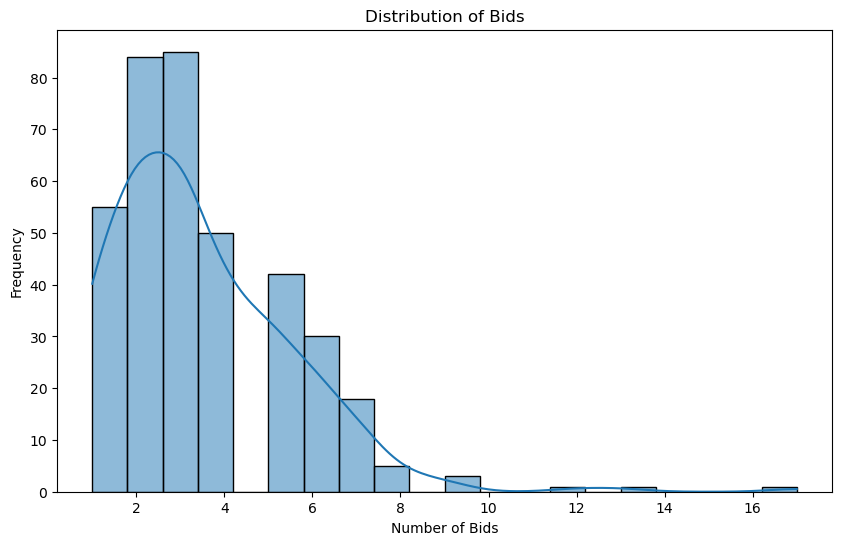

In [26]:
plt.figure(figsize=(10, 6))
sns.histplot(data=dfMGdataset_P2, x='R_bids', bins=20, kde=True)
plt.xlabel('Number of Bids')
plt.ylabel('Frequency')
plt.title('Distribution of Bids')
mean_bids = dfMGdataset_P2['R_bids'].mean()
print(f"The mean value for the bids distributions is: {mean_bids:.2f}")

In this next graph we divided the R_bids column depending on the level of competitiveness. The Y axis represents the frequency, so how many rows in our dataframe had each number of bets, which is represented in the X axis. We calculated the level of competitiveness with the quiartiles of the R_bids column, and got this result: up to 2 bids we have low competitivness, from 2 to 5 medium and from 6 bids there is high competitivness.

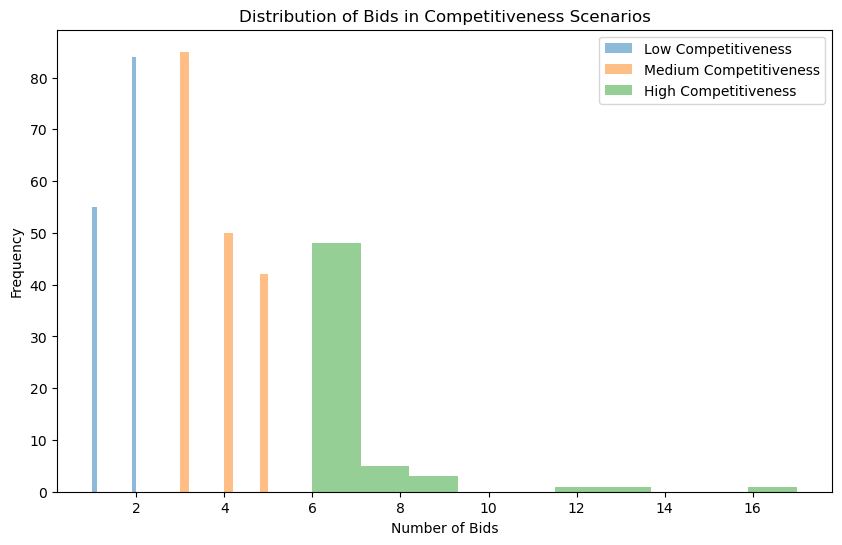

In [27]:
bids_summary = dfMGdataset_P2['R_bids'].describe()

low_quantile = dfMGdataset_P2 ['R_bids'].quantile(0.25)
high_quantile = dfMGdataset_P2 ['R_bids'].quantile(0.75)

dfMGdataset_P2['Competitiveness'] = pd.cut(dfMGdataset_P2['R_bids'], bins=[0, low_quantile, high_quantile, float('inf')],
                                labels=['Low', 'Medium', 'High'])
plt.figure(figsize=(10, 6))
plt.hist(dfMGdataset_P2[dfMGdataset_P2['Competitiveness'] == 'Low']['R_bids'], alpha=0.5, label='Low Competitiveness')
plt.hist(dfMGdataset_P2[dfMGdataset_P2['Competitiveness'] == 'Medium']['R_bids'], alpha=0.5, label='Medium Competitiveness')
plt.hist(dfMGdataset_P2[dfMGdataset_P2['Competitiveness'] == 'High']['R_bids'], alpha=0.5, label='High Competitiveness')
plt.xlabel('Number of Bids')
plt.ylabel('Frequency')
plt.legend()
plt.title('Distribution of Bids in Competitiveness Scenarios')
plt.show()

Also only 25 of the bids were open for further negotiation.

In [28]:
grouped_O_dnegotiated_dfMGdataset_P2 = dfMGdataset_P2.groupby('O_dnegotiated')
group_unique_O_dnegotiated_countsMGdataset_P2 = grouped_O_dnegotiated_dfMGdataset_P2.size()
group_unique_O_dnegotiated_countsMGdataset_P2

O_dnegotiated
0    367
1     25
dtype: int64

After that we decided to compare the data from the engineered price and the actual price that the products were sold at, and we realized that there were some sales so different appart from the mayority of the values we were going to analyze and might interfere with our trained model. At first sight, we decided to get rid of the three highest ones, but after training our models, we got a more accurate result by keeping them.

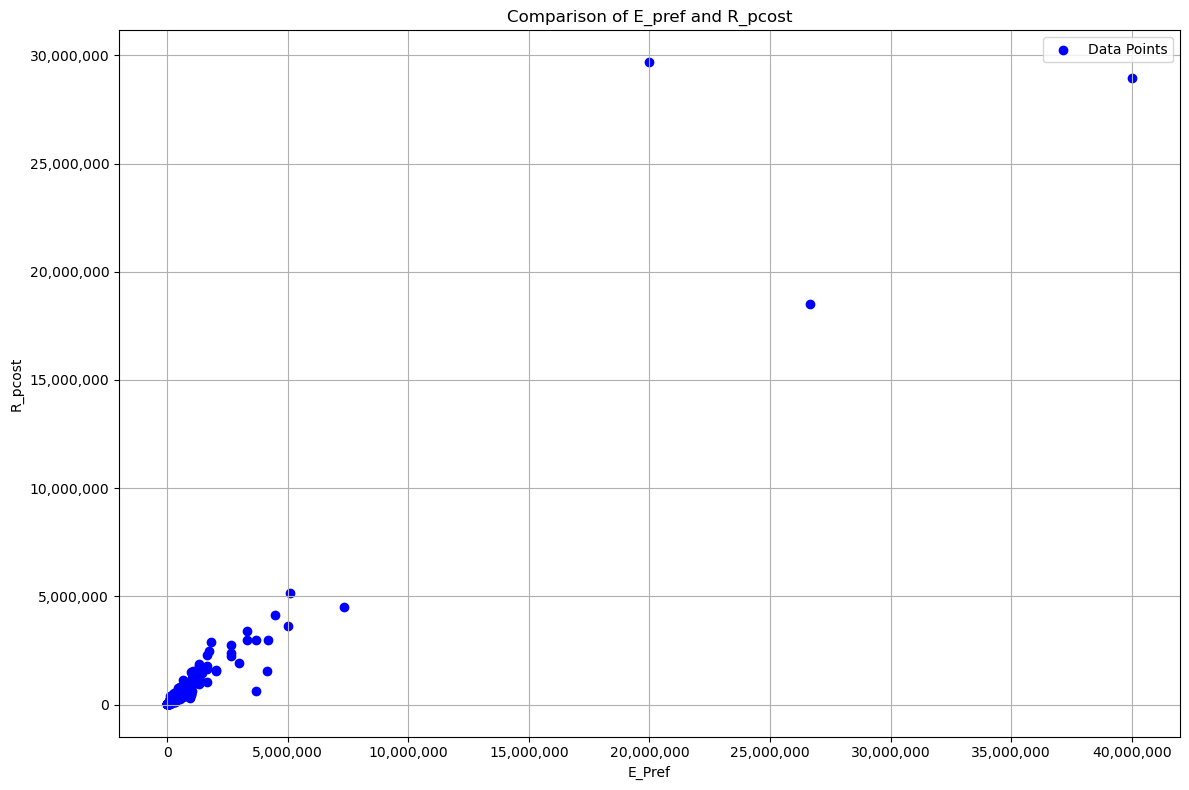

In [29]:
E_pref_values = dfMGdataset_P2['E_Pref'].astype(float)
R_pcost_values = dfMGdataset_P2['R_pcost'].astype(float)
plt.figure(figsize=(12, 8))
plt.scatter(E_pref_values, R_pcost_values, color='blue', label='Data Points')
plt.xlabel('E_Pref')
plt.ylabel('R_pcost')
plt.title('Comparison of E_pref and R_pcost')
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: '{:,.0f}'.format(x)))
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda x, _: '{:,.0f}'.format(x)))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


And we continue with a set of graphs to ease the visualization of data in many differnet ways

### <span style="color:blue">Step 2. Transformation of the data</span>

Before transformatin the data, we cheched if there were any duplicates, which we found out there weren't any.

In [30]:
duplicates_dfMGdataset_P2 = dfMGdataset_P2[dfMGdataset_P2.duplicated()] 
print (duplicates_dfMGdataset_P2)
duplicates_dfMGdataset_P2 = duplicates_dfMGdataset_P2.drop_duplicates()
duplicates_dfMGdataset_P2

Empty DataFrame
Columns: [O_order, O_code, O_dlots, O_Nlot, O_aval, O_daval, O_year_p, O_countryp_code, O_finstr, R_bids, R_dbids, O_dnegotiated, O_scope, E_Pref, R_pcost, E_indice, O_catpro, E_GDP_1, E_DTF_1, E_distance, viable, Competitiveness]
Index: []

[0 rows x 22 columns]


,O_order,O_code,O_dlots,O_Nlot,O_aval,O_daval,O_year_p,O_countryp_code,O_finstr,R_bids,...,O_scope,E_Pref,R_pcost,E_indice,O_catpro,E_GDP_1,E_DTF_1,E_distance,viable,Competitiveness


After that we checked for missing values, and the following columns are the ones with missing values in the dataset. 

In [31]:
rows_with_missing_values = dfMGdataset_P2[dfMGdataset_P2.isnull().any(axis=1)]
print("Rows with missing values:")
print(rows_with_missing_values)


Rows with missing values:
     O_order  O_code  O_dlots  O_Nlot   O_aval  O_daval  O_year_p  \
175      494  135407        1       4    200.0        1      2014   
176      495  135407        1       8    120.0        1      2014   
177      496  136883        1       1    150.0        1      2015   
178      497  136883        1       4    500.0        1      2015   
179      498  136883        1       5    400.0        1      2015   
180      499  137249        1       1   3800.0        1      2015   
181      501  137546        1       1  63000.0        1      2015   
182      502  137546        1       2  20000.0        1      2015   
183      503  137546        1       3  76500.0        1      2015   
184      504  137546        1       4  20000.0        1      2015   
185      505  137546        1       5   9500.0        1      2015   
186      506  137969        1       3   2870.0        1      2016   
387      493  131546        1       1  27500.0        1      2015   
388     

The missing values were for the R_bids column, so the number of bids recieved and the competitiveness (which we created to diferenciate the data). Since there were many with missing values, we decided to calculate the mean of the R_bids column for each year and each category and then filled the missing data in the R_bids column with those values.

In [32]:
print("Missing values before filling:")
print(dfMGdataset_P2['R_bids'].isnull().sum())


grouped_means = dfMGdataset_P2.groupby(['O_year_p', 'O_catpro'])['R_bids'].transform('mean')

# Use the fillna method to replace missing values in "R_dbids" with the group-specific mean
dfMGdataset_P2['R_bids'] = dfMGdataset_P2['R_bids'].fillna(round(grouped_means))

# Check the number of missing values in "R_dbids" after filling
print("Missing values after filling:")
print(dfMGdataset_P2['R_bids'].isnull().sum())


Missing values before filling:
17
Missing values after filling:
0


Here we filled all the missing values for R_bids with the means grouped by year and catpro. So we could get the most accurate picture of the whole dataset.

In [33]:
rows_with_missing_values = dfMGdataset_P2[dfMGdataset_P2.isnull().any(axis=1)]

print("Rows with missing values:")
print(rows_with_missing_values)

Rows with missing values:
     O_order  O_code  O_dlots  O_Nlot   O_aval  O_daval  O_year_p  \
175      494  135407        1       4    200.0        1      2014   
176      495  135407        1       8    120.0        1      2014   
177      496  136883        1       1    150.0        1      2015   
178      497  136883        1       4    500.0        1      2015   
179      498  136883        1       5    400.0        1      2015   
180      499  137249        1       1   3800.0        1      2015   
181      501  137546        1       1  63000.0        1      2015   
182      502  137546        1       2  20000.0        1      2015   
183      503  137546        1       3  76500.0        1      2015   
184      504  137546        1       4  20000.0        1      2015   
185      505  137546        1       5   9500.0        1      2015   
186      506  137969        1       3   2870.0        1      2016   
387      493  131546        1       1  27500.0        1      2015   
388     

As we see here now there are still missing values in Competitiveness (A category we created before just to create a pragh that will help us diferenciate the levels of competitiveness) but we are going to end up deleting it, so there is no need to fill in those values. We added this column for calcualtion for low, medium and high competetivtiveness. So we just did a calculation another calculation with the filled in R_bids values to get a whole picture of competetitiveness in the dataset. 

In [34]:
dfMGdataset_P2

,O_order,O_code,O_dlots,O_Nlot,O_aval,O_daval,O_year_p,O_countryp_code,O_finstr,R_bids,...,O_scope,E_Pref,R_pcost,E_indice,O_catpro,E_GDP_1,E_DTF_1,E_distance,viable,Competitiveness
0,119,131769,1,1,50000.0,1,2015,TK,IPA,1.0,...,0,3333333.33,2989000.00,0.8967,3,1025.467,72.83,2477,0,Low
1,121,133560,1,1,40000.0,1,2015,TK,IPA,1.0,...,0,2666666.67,2749000.00,1.0309,3,1025.467,72.83,2995,0,Low
2,125,135520,1,2,750.0,1,2015,SB,IPA,1.0,...,0,50000.00,39077.00,0.7815,3,39.882,72.48,1370,0,Low
3,126,135612,1,2,2500.0,1,2017,TK,IPA,1.0,...,0,166666.67,153580.00,0.9215,3,1122.512,73.26,2975,0,Low
4,130,135853,1,2,18581.0,1,2014,LB,ENI,1.0,...,0,1238733.33,1217912.00,0.9832,3,40.910,71.87,3136,0,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
387,493,131546,1,1,27500.0,1,2015,TK,IPA,3.0,...,0,1833333.33,2880996.30,1.5715,3,1025.467,72.83,2761,1,NaN
388,500,137249,1,2,1000.0,1,2015,JO,ENI,4.0,...,0,66666.67,54041.00,0.8106,2,29.501,78.20,3324,1,NaN
389,507,138256,1,1,3500.0,1,2016,ME,IPA,3.0,...,0,233333.33,348330.47,1.4928,2,4.529,79.37,1466,1,NaN
390,508,138256,1,2,6000.0,1,2016,ME,IPA,3.0,...,0,400000.00,580000.00,1.4500,2,4.529,79.37,1466,1,NaN


Now that there are no important missing values left. As mentioned before, the columns O_daval (that represents if there is a requirement for a bank deposit) and R_dbids (which represents if at least one valid bid was recieved), they only have one value, and they represent that there is always a requirement of a bank deposit and that always at least one bid was recieved, respectively (plus this last column is also not in the validation dataset), so we decided to drop them. 

As also mentioned before, the O_year_p and the O_countryp_code are also represented on the E_GDP_1 colums, since this column represents the Gross Domestic Product per capita, for each country and each year in the dataframe, those colums are represented, and then we decided to drop them.

Last but not least, since we have to train a model to fit the requirements of a validation dataset, we need to have the same columns when training the model and with the final data, then we dropped the E_Pref, R_pcost, and E_indice as well. 

In [35]:
dfMGdataset_P2 = dfMGdataset_P2.drop(columns=['O_daval', 'R_dbids', 'O_year_p', 'O_countryp_code', 'E_Pref', 'R_pcost', 'E_indice', 'Competitiveness'])

In [36]:
dfMGdataset_P2

,O_order,O_code,O_dlots,O_Nlot,O_aval,O_finstr,R_bids,O_dnegotiated,O_scope,O_catpro,E_GDP_1,E_DTF_1,E_distance,viable
0,119,131769,1,1,50000.0,IPA,1.0,0,0,3,1025.467,72.83,2477,0
1,121,133560,1,1,40000.0,IPA,1.0,0,0,3,1025.467,72.83,2995,0
2,125,135520,1,2,750.0,IPA,1.0,0,0,3,39.882,72.48,1370,0
3,126,135612,1,2,2500.0,IPA,1.0,1,0,3,1122.512,73.26,2975,0
4,130,135853,1,2,18581.0,ENI,1.0,0,0,3,40.910,71.87,3136,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
387,493,131546,1,1,27500.0,IPA,3.0,0,0,3,1025.467,72.83,2761,1
388,500,137249,1,2,1000.0,ENI,4.0,0,0,2,29.501,78.20,3324,1
389,507,138256,1,1,3500.0,IPA,3.0,0,0,2,4.529,79.37,1466,1
390,508,138256,1,2,6000.0,IPA,3.0,0,0,2,4.529,79.37,1466,1


### <span style="color:blue">Step 3. Training and testing machine learning models</span>

After understanding the values in out dataset and training the data, we started training some models and figuring out which one suited out dataset the best.

### Model 1 KNN (K-nearest neighbours)

In [37]:
all_features = ['O_order', 'O_code', 'O_dlots', 'O_Nlot', 'O_aval',
                'O_finstr', 'R_bids', 'O_dnegotiated', 'O_scope', 
                'O_catpro', 'E_GDP_1', 'E_DTF_1', 'E_distance']

categorical_features = ['O_finstr']
numerical_features = [feature for feature in all_features if feature not in categorical_features]

numeric_transformer = Pipeline(steps=[  
    ('scaler', StandardScaler()) 
])
categorical_transformer = Pipeline(steps=[ 
    ('onehot', OneHotEncoder(handle_unknown='ignore')) 
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

regr = Pipeline(steps=[
    ('preprocessor', preprocessor),
     ('knn', KNeighborsClassifier(n_neighbors=3)) 
])

x_train_KNN, x_test_KNN, y_train_KNN, y_test_KNN = train_test_split(dfMGdataset_P2.drop(columns=['viable']), dfMGdataset_P2['viable'],
test_size=0.33, random_state=42)

regr.fit(x_train_KNN, y_train_KNN)
y_predict = regr.predict(x_test_KNN)
Myscore = regr.score(x_test_KNN, y_test_KNN)
recall = recall_score(y_test_KNN, y_predict)
print(f"Accuracy: {Myscore}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test_KNN, y_predict)}")
print(f"Recall: {recall}")

Accuracy: 0.676923076923077
Balanced accuracy: 0.6870374791119599
Recall: 0.7966101694915254


/Users/rafaelhernandezperez/opt/anaconda3/lib/python3.9/site-packages/sklearn/neighbors/_classification.py:228: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)
/Users/rafaelhernandezperez/opt/anaconda3/lib/python3.9/site-packages/sklearn/neighbors/_classification.py:228: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and t

The first thing was telling the model all the features to calculate, and then to transform some of the features (categorical and numerical) using standard scaling for the numerical values and hot one encoding for the categorical ones. Then we defined the pipeline with the knn neighbours classifier and we dicided our data into training set and testing sets randomly to later calculate the  Accuracy and recall values and chose our best performing model.

This model for example, gave us a bad accuracy compared to what we were looking for but a decent recal. SO we decided to try another model. 

### Model 2 Logistic Regresion

In [38]:
all_features = ['O_order', 'O_code', 'O_dlots', 'O_Nlot', 'O_aval',
                'O_finstr', 'R_bids', 'O_dnegotiated', 'O_scope',
                'O_catpro', 'E_GDP_1', 'E_DTF_1', 'E_distance']

categorical_features = ['O_finstr']
numerical_features = [feature for feature in all_features if feature not in categorical_features]

numeric_transformer = Pipeline(steps=[  
    ('scaler', StandardScaler()) 
])
categorical_transformer = Pipeline(steps=[ 
    ('onehot', OneHotEncoder(handle_unknown='ignore')) 
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

LRClassifier = Pipeline(steps=[
    ('preprocessor', preprocessor),
     ('classifier', LogisticRegression()) 
])


x_train_LR, x_test_LR, y_train_LR, y_test_LR = train_test_split(dfMGdataset_P2.drop(columns=['viable']), dfMGdataset_P2['viable'],
test_size=0.33, random_state=42)

LRClassifier.fit(x_train_LR, y_train_LR)
y_predict = LRClassifier.predict(x_test_LR)
Myscore = LRClassifier.score(x_test_LR, y_test_LR)
recall = recall_score(y_test_LR, y_predict)
print(f"Accuracy: {Myscore}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test_LR, y_predict)}")
print(f"Recall: {recall}")

Accuracy: 0.7384615384615385
Balanced accuracy: 0.7505371210312723
Recall: 0.8813559322033898


This model gave us a slightly better accuracy, but still wasn't what we were looking for.

### Model 3 Decision Tree

In [39]:
all_features = ['O_order', 'O_code', 'O_dlots', 'O_Nlot', 'O_aval',
                'O_finstr', 'R_bids', 'O_dnegotiated', 'O_scope', 
                'O_catpro', 'E_GDP_1', 'E_DTF_1', 'E_distance']

categorical_features = ['O_finstr']
numerical_features = [feature for feature in all_features if feature not in categorical_features]



numeric_transformer = Pipeline(steps=[  
    ('scaler', StandardScaler())  
])
categorical_transformer = Pipeline(steps=[ 
    ('onehot', OneHotEncoder(handle_unknown='ignore'))  
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

treeClassifier = Pipeline(steps=[
    ('preprocessor', preprocessor),
     ('classifier', DecisionTreeClassifier(random_state=42)) 
])

x_train_tree, x_test_tree, y_train_tree, y_test_tree = train_test_split(dfMGdataset_P2.drop(columns=['viable']), dfMGdataset_P2['viable'],
test_size=0.33, random_state=42)



treeClassifier.fit(x_train_tree, y_train_tree)
y_predict = treeClassifier.predict(x_test_tree)
Myscore = treeClassifier.score(x_test_tree, y_test_tree)
print(f"Accuracy: {Myscore}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test_tree, y_predict)}")
recall = recall_score(y_test_LR, y_predict)
print(f"Recall: {recall}")

Accuracy: 0.8307692307692308
Balanced accuracy: 0.8350441632847935
Recall: 0.8813559322033898


Now the decision tree model really gave us higher accuracy, which is essentially what we are looking for, so then we decided to do some hyperparameter optimization, and tune the model in hopes for the result we needed.

In [40]:
#Model 3 DecisionTree with HPO

all_features = ['O_order', 'O_code', 'O_dlots', 'O_Nlot', 'O_aval', 
                'O_finstr', 'R_bids', 'O_dnegotiated', 'O_scope', 
                'O_catpro', 'E_GDP_1', 'E_DTF_1', 'E_distance']

categorical_features = ['O_finstr']
numerical_features = [feature for feature in all_features if feature not in categorical_features]



numeric_transformer = Pipeline(steps=[  
    ('scaler', StandardScaler()) 
])
categorical_transformer = Pipeline(steps=[ 
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

treeClassifier = Pipeline(steps=[
    ('preprocessor', preprocessor),
     ('classifier', DecisionTreeClassifier(random_state=42)) 
])

x_train_tree, x_test_tree, y_train_tree, y_test_tree = train_test_split(dfMGdataset_P2.drop(columns=['viable']), dfMGdataset_P2['viable'],
test_size=0.33, random_state=42)


# Define the hyperparameter grid to search
param_grid = {
    'classifier__max_depth':list (range(2,16,2)),
    'classifier__min_samples_split': list (range(2,14,2)),
}

inner=KFold(n_splits=5, shuffle=True, random_state=42)

# Create a GridSearchCV object with the pipeline and hyperparameter grid
grid_search = GridSearchCV(estimator=treeClassifier, param_grid=param_grid, scoring='accuracy', cv=inner)

# Fit the GridSearchCV to your training data
grid_search.fit(x_train_tree, y_train_tree)

# Get the best hyperparameters and best estimator
best_params = grid_search.best_params_
best_estimator = grid_search.best_estimator_

# Make predictions and evaluate the model
y_predict = best_estimator.predict(x_test_tree)
Myscore = best_estimator.score(x_test_tree, y_test_tree)
print(f"Best Hyperparameters: {best_params}")
print(f"Accuracy: {Myscore}")


Best Hyperparameters: {'classifier__max_depth': 8, 'classifier__min_samples_split': 2}
Accuracy: 0.8153846153846154


By defining a hyperparameter grid to serch inside the model adn adjusting the values like 'classifier__max_depth', 'classifier__min_samples_split', and the cross validation, we hoped to get more accuret results, but that was not the case so we continued looking for other alternative models. 

### Model 4 Polynomy

In [41]:
all_features = ['O_order', 'O_code', 'O_dlots', 'O_Nlot', 'O_aval', 
                'O_finstr', 'R_bids', 'O_dnegotiated', 'O_scope',
                'O_catpro', 'E_GDP_1', 'E_DTF_1', 'E_distance']

categorical_features = ['O_finstr']
numerical_features = [feature for feature in all_features if feature not in categorical_features]

x_train_poly, x_test_poly, y_train_poly, y_test_poly = train_test_split(dfMGdataset_P2.drop(columns=['viable']), dfMGdataset_P2['viable'],
test_size=0.33, random_state=42)

numeric_transformer = Pipeline(steps=[  
    ('scaler', StandardScaler())  
])
categorical_transformer = Pipeline(steps=[ 
    ('onehot', OneHotEncoder(handle_unknown='ignore')) 
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

x_train_poly = preprocessor.fit_transform(x_train_poly)

x_test_poly = preprocessor.transform(x_test_poly)
degree = 2 

poly_features = PolynomialFeatures(degree=degree)

x_train_poly = poly_features.fit_transform(x_train_poly)
x_test_poly = poly_features.transform(x_test_poly)

rf_classifier = RandomForestClassifier(random_state=42)

rf_classifier.fit(x_train_poly, y_train_poly)

y_pred_poly = rf_classifier.predict(x_test_poly)

accuracy_poly = accuracy_score(y_test_poly, y_pred_poly)
print(f"Accuracy: {accuracy_poly}")
recall = recall_score(y_test_poly, y_predict)
print(f"Recall: {recall}")

Accuracy: 0.823076923076923
Recall: 0.9322033898305084


After that we tried with this new model, which also gave us decent results, but not what we were looking for. And since the Decistion Tree model had been the best one so far we found a variation of it called Random Forest model, so we tried it as well.

### Model 5 Random Forest

In [42]:
all_features = ['O_order', 'O_code', 'O_dlots', 'O_Nlot', 'O_aval', 
                'O_finstr', 'R_bids', 'O_dnegotiated', 'O_scope', 
                'O_catpro', 'E_GDP_1', 'E_DTF_1', 'E_distance']

categorical_features = ['O_finstr']
numerical_features = [feature for feature in all_features if feature not in categorical_features]


numeric_transformer = Pipeline(steps=[  
    ('scaler', StandardScaler()) 
])
categorical_transformer = Pipeline(steps=[ 
    ('onehot', OneHotEncoder(handle_unknown='ignore')) 
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])



treeClassifier = Pipeline(steps=[
    ('preprocessor', preprocessor),
     ('classifier', RandomForestClassifier(random_state=42)) 
])

x_train_tree, x_test_tree, y_train_tree, y_test_tree = train_test_split(dfMGdataset_P2.drop(columns=['viable']), dfMGdataset_P2['viable'],
test_size=0.33, random_state=42)

treeClassifier.fit(x_train_tree, y_train_tree)
y_predict = treeClassifier.predict(x_test_tree)

Myscore = treeClassifier.score(x_test_tree, y_test_tree)
print(f"Accuracy: {Myscore}")
recall = recall_score(y_test_tree, y_predict)
print(f"Recall: {recall}")

Accuracy: 0.8307692307692308
Recall: 0.8983050847457628


So far this was our most accurate model at predicting, so we did some hyperparameter optimization and we got the final model.

## BEST MODEL

In [43]:
#Model 5 RandomForest with HPO

all_features = ['O_order', 'O_code', 'O_dlots', 'O_Nlot', 'O_aval',
                'O_finstr', 'R_bids', 'O_dnegotiated', 'O_scope', 
                'O_catpro', 'E_GDP_1', 'E_DTF_1', 'E_distance']

categorical_features = ['O_finstr']
numerical_features = [feature for feature in all_features if feature not in categorical_features]

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

param_grid = {
    'classifier__max_depth': [None, 25, 25, 45],  
    'classifier__min_samples_split': [10, 15, 25, 35],  
    'classifier__min_samples_leaf': [1, 2, 4],  
    'classifier__max_features': ['sqrt', 'log2', None]  
}

treeClassifier = Pipeline(steps=[
    ('preprocessor', preprocessor),
     ('classifier', RandomForestClassifier(random_state=42)) 
])

inner=KFold(n_splits=7, shuffle=True, random_state=42)

grid_search = GridSearchCV(estimator=treeClassifier, param_grid=param_grid, scoring='accuracy', cv=inner)

x_train_tree, x_test_tree, y_train_tree, y_test_tree = train_test_split(dfMGdataset_P2.drop(columns=['viable']), dfMGdataset_P2['viable'],
test_size=0.33, random_state=42)

grid_search.fit(x_train_tree, y_train_tree)

best_params = grid_search.best_params_
random_forest_model = grid_search.best_estimator_

y_predict = random_forest_model.predict(x_test_tree)

accuracy = accuracy_score(y_test_tree, y_predict)
balanced_accuracy = balanced_accuracy_score(y_test_tree, y_predict)

print(f"Accuracy: {accuracy}")
print(f"Balanced Accuracy: {balanced_accuracy}")
print(f"Best Hyperparameters: {best_params}")
recall = recall_score(y_test_tree, y_predict)
print(f"Recall: {recall}")

Accuracy: 0.8692307692307693
Balanced Accuracy: 0.8731200763905467
Best Hyperparameters: {'classifier__max_depth': None, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 10}
Recall: 0.9152542372881356


In this final model we defined a hyperparameter grid (by adjusting the depgh of the tree, the number of samples required to split the internal node, the minimum number to be a leaf node adn the number of features to consider on each split) and we used kfold evaluation for the cross validation of the data to get the most accurate results possible, and in fact we got the best accuracy out of all the other models  and a pretty good recall as well. So we decided that this was the model we were going to test on the verification data.

Finally, we trained the model one more time with the full dataset, to get more accurate results on our validation data.

In [44]:
x_train_full = dfMGdataset_P2.drop(columns=['viable'])
y_train_full = dfMGdataset_P2['viable']
random_forest_model.fit(x_train_full, y_train_full)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['O_order', 'O_code',
                                                   'O_dlots', 'O_Nlot',
                                                   'O_aval', 'R_bids',
                                                   'O_dnegotiated', 'O_scope',
                                                   'O_catpro', 'E_GDP_1',
                                                   'E_DTF_1', 'E_distance']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
 

### <span style="color:blue">Step 4. Best behaving model for prediction purposes</span>

Once we had the best predictive model we downloaded it into a joblib file and we used it later on to predict the values in the Validation dataset (on another notebook)

In [45]:
import joblib

joblib.dump(random_forest_model, 'P2_RANDOMFORESTmodel.joblib')

['P2_RANDOMFORESTmodel.joblib']